<div style="font-family:'Segoe UI',Roboto,Helvetica,Arial,sans-serif;max-width:900px;margin:0 auto;border-radius:16px;overflow:hidden;box-shadow:0 4px 20px rgba(0,0,0,0.12);border:1px solid #e2e2e2;">

<div style="background:linear-gradient(135deg,#002855 0%,#004b8d 55%,#0077c8 100%);padding:28px 20px 22px 20px;text-align:center;">
<img src="./img/ITESOLogo.png" alt="ITESO" width="260" style="margin-bottom:10px;">
<div style="color:#ffffff;font-size:15px;font-weight:600;letter-spacing:0.5px;text-transform:uppercase;opacity:0.9;">
Departamento de Electrónica, Sistemas e Informática
</div>
</div>

<div style="background-color:#ffffff;padding:26px 30px 30px 30px;text-align:center;">

<div style="color:#002855;font-size:26px;font-weight:800;margin-bottom:6px;">
Big Data Analysis
</div>

<div style="display:inline-block;background-color:#eaf4fb;color:#0077c8;font-size:13px;font-weight:700;padding:4px 14px;border-radius:20px;letter-spacing:0.5px;margin-bottom:22px;">
Autumn 2026
</div>


<hr style="border:none;border-top:2px solid #f0f0f0;margin:0 0 22px 0;">

<div style="background-color:#f7fafd;border-left:5px solid #0077c8;border-radius:8px;padding:14px 18px;text-align:left;margin-bottom:18px;">
<div style="font-size:12px;color:#7a7a7a;font-weight:600;text-transform:uppercase;letter-spacing:0.5px;margin-bottom:4px;">
Session 17
</div>
<div style="font-size:19px;color:#002855;font-weight:700;">
Big Data - Structured Streaming (Apache Kafka + Spark)
</div>
</div>

<div style="font-size:14px;color:#444;margin-top:20px;">
<span style="font-weight:700;color:#002855;">Profesor:</span> Pablo Camarillo Ramírez
</div>

</div>
</div>

# Create SparkSession

In [1]:
from pcamarillor.spark_utils import SparkUtils
from pathlib import Path
import shutil
import pyspark.sql.functions as F

kafka_connector = "org.apache.spark:spark-sql-kafka-0-10_2.13:4.1.3"
su = SparkUtils("Example Kafka", 
                "local[*]",
                spark_packages=kafka_connector)
su.spark


:: loading settings :: url = jar:file:/opt/spark/jars/ivy-2.5.3.jar!/org/apache/ivy/core/settings/ivysettings.xml
Ivy Default Cache set to: /root/.ivy2.5.2/cache
The jars for the packages stored in: /root/.ivy2.5.2/jars
org.apache.spark#spark-sql-kafka-0-10_2.13 added as a dependency
:: resolving dependencies :: org.apache.spark#spark-submit-parent-c7cb803c-f462-48ac-b06f-70b248f0c526;1.0
	confs: [default]
	found org.apache.spark#spark-sql-kafka-0-10_2.13;4.1.3 in central
	found org.apache.spark#spark-token-provider-kafka-0-10_2.13;4.1.3 in central
	found org.apache.kafka#kafka-clients;3.9.1 in central
	found org.lz4#lz4-java;1.8.0 in central
	found org.xerial.snappy#snappy-java;1.1.10.8 in central
	found org.slf4j#slf4j-api;2.0.17 in central
	found org.apache.hadoop#hadoop-client-runtime;3.4.2 in central
	found org.apache.hadoop#hadoop-client-api;3.4.2 in central
	found com.google.code.findbugs#jsr305;3.0.0 in central
	found org.scala-lang.modules#scala-parallel-collections_2.13;1.2.0

## Experiment 1: Create a data stream from a Kafka topic

### Producer

### Create a topic in Kafka

    docker exec -it <kafka container id> /opt/kafka/bin/kafka-topics.sh --create --zookeeper zookeeper:2181 --replication-factor 1 --partitions 1 --topic kafka-spark-example

### Start publishing messages

    docker exec -it <kafka container id> /opt/kafka/bin/kafka-console-producer.sh --broker-list localhost:9092 --topic kafka-spark-example

### Consumer

In [2]:
# Create the remote connection
kafka_df = su.spark.readStream \
            .format("kafka") \
            .option("kafka.bootstrap.servers", "kafka:9093") \
            .option("subscribe", "kafka-spark-example") \
            .load()

kafka_df.printSchema()

# Transform binary data to string
df_input = kafka_df.selectExpr("CAST(value AS STRING)")

# Clean checkpoint
checkpoint_path = "/opt/spark/work-dir/checkpoints/logs_checkpoint"
dir_path = Path(checkpoint_path)
if dir_path.exists() and dir_path.is_dir():
    shutil.rmtree(dir_path)

words = df_input.select(F.explode(F.split(df_input.value, " ")).alias("word"))
word_count = words.groupBy("word").count()

# Send transformed data to the Sink
query_a = (word_count.writeStream
            .trigger(processingTime='2 second')
            .outputMode("complete")
            .format("console")
            .option("checkpointLocation", checkpoint_path)
            .start())


root
 |-- key: binary (nullable = true)
 |-- value: binary (nullable = true)
 |-- topic: string (nullable = true)
 |-- partition: integer (nullable = true)
 |-- offset: long (nullable = true)
 |-- timestamp: timestamp (nullable = true)
 |-- timestampType: integer (nullable = true)



26/10/27 02:52:11 WARN ResolveWriteToStream: spark.sql.adaptive.enabled is not supported in streaming DataFrames/Datasets and will be disabled.
26/10/27 02:52:11 WARN MicroBatchExecution: Disabling AQE since AQE is not supported in stateful workloads.


-------------------------------------------
Batch: 0
-------------------------------------------
+----+-----+
|word|count|
+----+-----+
+----+-----+



26/10/27 02:52:13 WARN ProcessingTimeExecutor: Current batch is falling behind. The trigger interval is 2000 milliseconds, but spent 2089 milliseconds
                                                                                

-------------------------------------------
Batch: 1
-------------------------------------------
+-----+-----+
| word|count|
+-----+-----+
|world|    1|
|hello|    1|
+-----+-----+

-------------------------------------------
Batch: 2
-------------------------------------------
+-----+-----+
| word|count|
+-----+-----+
|world|    1|
|again|    1|
|hello|    2|
+-----+-----+



## Experiment 2: Custom producer -> Apache Kafka -> Apache Spark
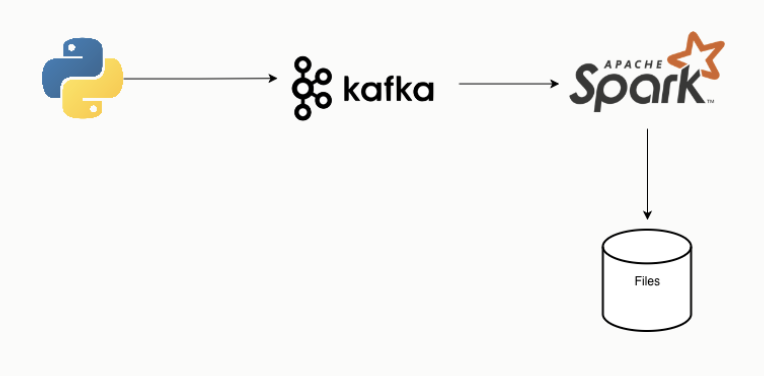

In [3]:
!pip install kafka-python

### Create `server-logs` topic

```
    docker exec -it <Kafka container ID> /opt/kafka/bin/kafka-topics.sh --create --zookeeper zookeeper:2181 --replication-factor 1 --partitions 1 --topic server-logs
```

### Run the producer

```
    docker exec -it <Spark-Notebook container ID> /bin/bash
    # cd src/producers/
    # python3 kafka_producer.py --broker kafka:9093 --topic server-logs --records 20
```

### Run the consumer code

In [4]:
!ls /opt/spark/work-dir/data/streaming/output/

ls: cannot access '/opt/spark/work-dir/data/streaming/output/': No such file or directory


In [5]:
# Create the remote connection
server_logs_df = (su.spark.readStream
            .format("kafka")
            .option("kafka.bootstrap.servers", "kafka:9093")
            .option("subscribe", "server-logs")
            .load())

# Transform binary data to string
logs_df = server_logs_df.selectExpr("CAST(value AS STRING)")

# Clean checkpoint
checkpoint_path = "/opt/spark/work-dir/checkpoints/logs_checkpoint"
dir_path = Path(checkpoint_path)
if dir_path.exists() and dir_path.is_dir():
    shutil.rmtree(dir_path)

# Transform original dataframe
parsed_df = (
    logs_df
    .withColumn("parts",     F.split(F.col("value"), r" \| "))
    .withColumn("timestamp", F.to_timestamp(F.col("parts")[0], "yyyy-MM-dd HH:mm:ss"))
    .withColumn("level",     F.trim(F.col("parts")[1]))
    .withColumn("message",   F.trim(F.col("parts")[2]))
    .withColumn("server",    F.trim(F.col("parts")[3]))
    .drop("parts", "value")
    .filter(F.col("timestamp").isNotNull())
)

# Write stream in the destination
output_path = "/opt/spark/work-dir/data/streaming/output/"
query_events = (
    parsed_df.writeStream
    .outputMode("append")
    .format("parquet")
    .option("truncate", False)
    .option("checkpointLocation", checkpoint_path)
    .option("path", output_path)
    .partitionBy("server", "level")
    .start()
)
su.spark.streams.awaitAnyTermination()

26/10/27 03:09:58 WARN ResolveWriteToStream: spark.sql.adaptive.enabled is not supported in streaming DataFrames/Datasets and will be disabled.
ERROR:root:KeyboardInterrupt while sending command.                             
Traceback (most recent call last):
  File "/opt/spark/python/lib/py4j-0.10.9.9-src.zip/py4j/java_gateway.py", line 1038, in send_command
    response = connection.send_command(command)
  File "/opt/spark/python/lib/py4j-0.10.9.9-src.zip/py4j/clientserver.py", line 535, in send_command
    answer = smart_decode(self.stream.readline()[:-1])
  File "/usr/lib/python3.10/socket.py", line 705, in readinto
    return self._sock.recv_into(b)
KeyboardInterrupt


KeyboardInterrupt: 

In [ ]:
!ls -lah /opt/spark/work-dir/data/streaming/output/

# Producer evidence
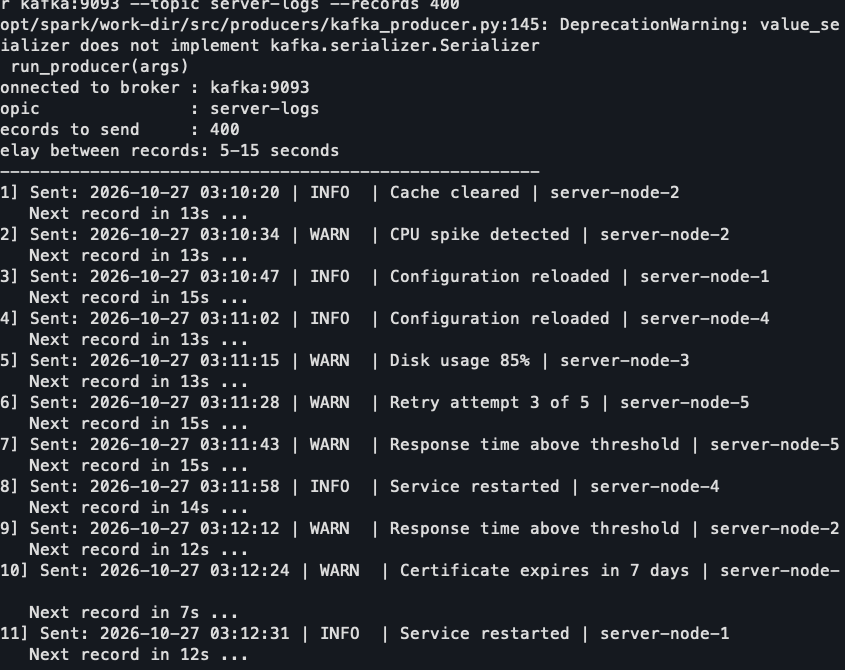

# Evidence of the output location
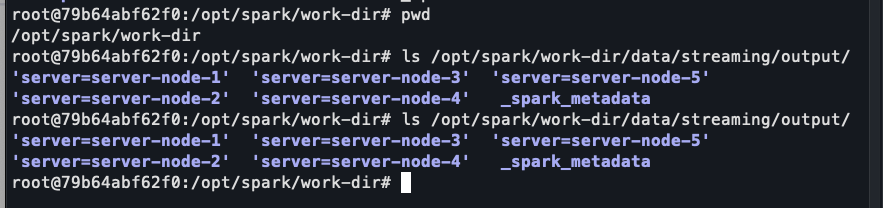

In [6]:
su.spark.stop()

26/10/27 03:15:13 WARN StateStore: Error running maintenance thread
java.lang.IllegalStateException: SparkEnv not active, cannot do maintenance on StateStores
	at org.apache.spark.sql.execution.streaming.state.StateStore$.doMaintenance(StateStore.scala:1440)
	at org.apache.spark.sql.execution.streaming.state.StateStore$.$anonfun$startMaintenanceIfNeeded$1(StateStore.scala:1386)
	at org.apache.spark.sql.execution.streaming.state.StateStore$MaintenanceTask$$anon$1.run(StateStore.scala:1079)
	at java.base/java.util.concurrent.Executors$RunnableAdapter.call(Executors.java:539)
	at java.base/java.util.concurrent.FutureTask.runAndReset(FutureTask.java:305)
	at java.base/java.util.concurrent.ScheduledThreadPoolExecutor$ScheduledFutureTask.run(ScheduledThreadPoolExecutor.java:305)
	at java.base/java.util.concurrent.ThreadPoolExecutor.runWorker(ThreadPoolExecutor.java:1136)
	at java.base/java.util.concurrent.ThreadPoolExecutor$Worker.run(ThreadPoolExecutor.java:635)
	at java.base/java.lang.Thre